# Гибридная идентификация нелинейных динамических систем: нейросеть + статический и адаптивный EKF

В работе исследуется гибридная схема **Neural State-Space Model + Extended Kalman Filter (EKF)** на трёх наборах данных DaISy:

- **[96-006] Hair Dryer** — SISO;
- **[99-001] Heating System** — SISO;
- **[96-016] Industrial Dryer** — MIMO, 3 входа и 3 выхода.

Сравниваются пять нейросетевых архитектур: **ENN**, **LSTM**, **GRU**, **TCN** и **MLP с окном задержки**. Для каждой сравниваются статический EKF и адаптивный EKF Акхлаги–Чжоу–Хуана.

Схема гибрида сохраняет основной принцип Hu et al. (2021): нейросеть задаёт нелинейную модель перехода состояния, EKF корректирует скрытое состояние по текущему измерению, а исправленное состояние возвращается в нейросеть на следующем шаге.

После начала прогнозируемого участка текущее измерение не подаётся в нейросеть напрямую. Оно используется только на шаге коррекции EKF.

`Q0` и `R0` подбираются только на валидационной выборке. В статическом EKF они фиксированы; в адаптивном служат начальными матрицами. Параметр `tau` также выбирается только на VAL и затем фиксируется.

## 1. Настройки эксперимента

In [1]:
from pathlib import Path
from copy import deepcopy
import gzip
import json
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn

from IPython.display import display

SEED = 42

EPOCHS = 120
CHECK_EVERY = 5
PATIENCE = 7
MIN_FINAL_EPOCHS = 20  # Минимум эпох на последнем горизонте до ранней остановки
BATCH_SIZE = 32
BATCHES_PER_EPOCH = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

NORMAL_NOISE = 0.10
NOISE_LEVELS = {
    'Малый': 0.05,
    'Нормальный': 0.10,
    'Большой': 0.20,
}

Q_GRID = [1e-5, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
R_MULTIPLIERS = [0.10, 0.25, 0.50, 1.0, 2.0]
P0_ALPHA = 1.0
TAU_GRID = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.985]
COVARIANCE_EPS = 1e-12  # Малая добавка на диагональ против ошибок округления
ARCHITECTURES = ['ENN', 'LSTM', 'GRU', 'TCN', 'MLP']

MC_VAL = 3
MC_TEST = 20
MC_ROBUST = 10

CANDIDATES = {
    'ENN': [
        {'hidden': 16, 'init_window': 16},
        {'hidden': 32, 'init_window': 32},
    ],
    'GRU': [
        {'hidden': 16, 'init_window': 16},
        {'hidden': 32, 'init_window': 32},
    ],
    'LSTM': [
        {'hidden': 16, 'init_window': 16},
        {'hidden': 32, 'init_window': 32},
    ],
    'TCN': [
        {'hidden': 16, 'control_window': 16, 'init_window': 16},
        {'hidden': 32, 'control_window': 32, 'init_window': 32},
    ],
    'MLP': [
        {'hidden': 16, 'control_window': 16, 'init_window': 16},
        {'hidden': 32, 'control_window': 32, 'init_window': 32},
    ],
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

RESULTS_DIR = Path('daisy_hu_results')
RESULTS_DIR.mkdir(exist_ok=True)

print('Устройство:', DEVICE)
print('Папка результатов:', RESULTS_DIR.resolve())

Устройство: cuda
Папка результатов: /kaggle/working/daisy_hu_results


## 2. Данные DaISy

Разбиение выполняется строго по времени: **60% TRAIN / 20% VAL / 20% TEST**.

Статистики нормализации вычисляются только по TRAIN.

Для Industrial Dryer используются все три входа и все три выхода. Главным исследуемым выходом остаётся `y3` - влажность материала.
Исходные записи - условный эталон: они сами могут содержать измерительные ошибки.
Добавленный шум задаётся в долях стандартного отклонения TRAIN каждого выхода.
Например, `sigma=0.10` означает стандартное отклонение 0.10 после нормализации,
а в исходном масштабе выхода j — `0.10 * y_std[j]`.

Для Heating официальный источник указывает °C. В описаниях Hair Dryer и Industrial
Dryer единицы масштаба выходных столбцов явно не заданы: обозначение «ед. исходного
файла».


In [2]:
DATASET_CONFIGS = {
    '96-006': {
        'name': 'Лабораторный фен',
        'filename': 'dryer.dat.gz',
        'url': 'https://ftp.esat.kuleuven.be/pub/SISTA/data/mechanical/dryer.dat.gz',
        'n_inputs': 1,
        'n_outputs': 1,
        'expected_samples': 1000,
        'target_index': 0,
        'output_names': ['Температура воздуха'],
        'output_units': ['ед. исходного файла'],
        'mode': 'SISO',
    },
    '99-001': {
        'name': 'Система отопления',
        'filename': 'heating_system.dat.gz',
        'url': 'https://ftp.esat.kuleuven.be/pub/SISTA/data/thermic/heating_system.dat.gz',
        'n_inputs': 1,
        'n_outputs': 1,
        'expected_samples': 801,
        'target_index': 0,
        'output_names': ['Температура'],
        'output_units': ['°C'],
        'mode': 'SISO',
    },
    '96-016': {
        'name': 'Промышленная сушилка',
        'filename': 'dryer2.dat.gz',
        'url': 'https://ftp.esat.kuleuven.be/pub/SISTA/data/process_industry/dryer2.dat.gz',
        'n_inputs': 3,
        'n_outputs': 3,
        'expected_samples': 867,
        'target_index': 2,
        'output_names': [
            'Температура сухого термометра',
            'Температура влажного термометра',
            'Влажность материала',
        ],
        'output_units': ['ед. исходного файла'] * 3,
        'mode': 'MIMO',
    },
}


def find_local_file(filename):
    candidates = [
        Path(filename),
        Path('data') / filename,
        Path('daisy_data') / filename,
    ]

    if Path('/kaggle/input').exists():
        candidates += list(Path('/kaggle/input').rglob(filename))

    for path in candidates:
        if path.is_file():
            return path

    return None


def download_file(url, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})

    try:
        with urllib.request.urlopen(request, timeout=90) as response:
            contents = response.read()
    except Exception as error:
        raise RuntimeError(
            f'Не удалось скачать {path.name}'
        ) from error

    path.write_bytes(contents)


def read_numeric_gzip(path):
    with gzip.open(path, 'rt', encoding='latin1') as file:
        text = file.read()

    rows = []

    for line in text.splitlines():
        parts = line.strip().replace(',', ' ').split()

        if not parts:
            continue

        try:
            rows.append([
                float(value.replace('D', 'E').replace('d', 'e'))
                for value in parts
            ])
        except ValueError:
            continue

    if not rows:
        raise RuntimeError(f'В файле {path} не найдено числовых данных')

    widths = [len(row) for row in rows]
    width = max(set(widths), key=widths.count)
    rows = [row for row in rows if len(row) == width]

    return np.asarray(rows, dtype=float)


def load_dataset(code):
    config = DATASET_CONFIGS[code]
    path = find_local_file(config['filename'])

    if path is None:
        path = Path('daisy_data') / config['filename']

        if not path.exists():
            print('Скачиваем', code, '...')
            download_file(config['url'], path)

    matrix = read_numeric_gzip(path)
    data_columns = config['n_inputs'] + config['n_outputs']

    if matrix.shape[1] == data_columns:
        offset = 0
    elif matrix.shape[1] == data_columns + 1:
        offset = 1
    else:
        raise RuntimeError(
            f'{code}: найдено {matrix.shape[1]} столбцов, '
            f'ожидалось {data_columns} или {data_columns + 1}.'
        )

    u = matrix[:, offset:offset + config['n_inputs']]
    y = matrix[:, offset + config['n_inputs']:offset + data_columns]

    good = np.all(np.isfinite(u), axis=1) & np.all(np.isfinite(y), axis=1)
    u = u[good]
    y = y[good]

    if len(y) != config['expected_samples']:
        raise RuntimeError(
            f'{code}: ожидалось {config["expected_samples"]} точек, получено {len(y)}.'
        )

    train_end = int(0.60 * len(y))
    val_end = int(0.80 * len(y))

    u_mean = u[:train_end].mean(axis=0)
    u_std = u[:train_end].std(axis=0)
    u_std[u_std < 1e-12] = 1.0

    y_mean = y[:train_end].mean(axis=0)
    y_std = y[:train_end].std(axis=0)
    y_std[y_std < 1e-12] = 1.0

    return {
        'code': code,
        'name': config['name'],
        'mode': config['mode'],
        'target_index': config['target_index'],
        'output_names': config['output_names'],
        'output_units': config['output_units'],
        'u': u,
        'y': y,
        'u_norm': ((u - u_mean) / u_std).astype(np.float32),
        'y_norm': ((y - y_mean) / y_std).astype(np.float32),
        'u_mean': u_mean,
        'u_std': u_std,
        'y_mean': y_mean,
        'y_std': y_std,
        'train_end': train_end,
        'val_end': val_end,
    }


datasets = {
    code: load_dataset(code)
    for code in DATASET_CONFIGS
}

info_rows = []

for code, data in datasets.items():
    info_rows.append({
        'Код': code,
        'Датасет': data['name'],
        'Схема': data['mode'],
        'Точек': len(data['y']),
        'Входов': data['u'].shape[1],
        'Выходов': data['y'].shape[1],
        'TRAIN': data['train_end'],
        'VAL': data['val_end'] - data['train_end'],
        'TEST': len(data['y']) - data['val_end'],
    })

display(pd.DataFrame(info_rows))

,Код,Датасет,Схема,Точек,Входов,Выходов,TRAIN,VAL,TEST
0,96-006,Лабораторный фен,SISO,1000,1,1,600,200,200
1,99-001,Система отопления,SISO,801,1,1,480,160,161
2,96-016,Промышленная сушилка,MIMO,867,3,3,520,173,174


## 3. Нейросетевые модели состояния

Для LSTM состоянием EKF является объединённый вектор `[h, c]`.

TCN и MLP кодируют окно предыдущих управляющих воздействий и обновляют явное состояние через gated-переход.

Начальное состояние оценивается по предыдущему наблюдаемому фрагменту `(u, y)`. После начала rollout истинный `y` в нейросеть больше не передаётся.

**ENN:** явное скрытое состояние `h`, сигмоидальный переход от `[h, u]` и
линейное наблюдение.
Для сопоставимости с остальными сетями начальное состояние здесь тоже обучаемое (это расширение исходного подхода).

**GRU:** состояние `h`, переход через `GRUCell`, линейное наблюдение.
Обе новые модели получают то же прошлое управление `u[k-1]`, что и LSTM.
У всех пяти моделей следующий переход использует исправленное фильтром состояние.


In [3]:
class StateInitializer(nn.Module):
    def __init__(self, n_inputs, n_outputs, init_window, state_dim, width):
        super().__init__()
        input_dim = init_window * (n_inputs + n_outputs)

        self.net = nn.Sequential(
            nn.Linear(input_dim, width),
            nn.Tanh(),
            nn.Linear(width, width),
            nn.Tanh(),
            nn.Linear(width, state_dim),
        )

    def forward(self, u_history, y_history):
        values = torch.cat([u_history, y_history], dim=2)
        return self.net(values.reshape(values.shape[0], -1))


class LSTMStateModel(nn.Module):
    def __init__(self, n_inputs, n_outputs, hidden, init_window):
        super().__init__()
        self.arch = 'LSTM'
        self.hidden = hidden
        self.state_dim = 2 * hidden
        self.control_window = 1
        self.init_window = init_window

        self.initializer = StateInitializer(
            n_inputs,
            n_outputs,
            init_window,
            self.state_dim,
            width=max(32, 2 * hidden),
        )

        self.cell = nn.LSTMCell(n_inputs, hidden)
        self.output_layer = nn.Linear(hidden, n_outputs)

    def initial_state(self, u_history, y_history):
        return self.initializer(u_history, y_history)

    def encode_control(self, context):
        return context[:, -1, :]

    def transition_feature(self, state, feature):
        h = state[:, :self.hidden]
        c = state[:, self.hidden:]
        h_new, c_new = self.cell(feature, (h, c))
        return torch.cat([h_new, c_new], dim=1)

    def observe(self, state):
        return self.output_layer(state[:, :self.hidden])

    def observation_matrix(self):
        zeros = torch.zeros(
            self.output_layer.out_features,
            self.hidden,
            device=self.output_layer.weight.device,
            dtype=self.output_layer.weight.dtype,
        )
        return torch.cat([self.output_layer.weight, zeros], dim=1)


class CausalBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()
        self.padding = 2 * dilation
        self.conv = nn.Conv1d(channels, channels, kernel_size=3, dilation=dilation)
        self.mix = nn.Conv1d(channels, channels, kernel_size=1)

    def forward(self, values):
        padded = nn.functional.pad(values, (self.padding, 0))
        change = self.mix(torch.tanh(self.conv(padded)))
        return torch.tanh(values + change)


class TCNEncoder(nn.Module):
    def __init__(self, n_inputs, window, width):
        super().__init__()
        self.input_layer = nn.Conv1d(n_inputs, width, kernel_size=1)
        dilations = [d for d in [1, 2, 4, 8, 16, 32] if d < window]
        self.blocks = nn.ModuleList([
            CausalBlock(width, dilation)
            for dilation in dilations
        ])

    def forward(self, context):
        values = self.input_layer(context.transpose(1, 2))

        for block in self.blocks:
            values = block(values)

        return values[:, :, -1]


class MLPEncoder(nn.Module):
    def __init__(self, n_inputs, window, width):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_inputs * window, width),
            nn.Tanh(),
            nn.Linear(width, width),
            nn.Tanh(),
        )

    def forward(self, context):
        return self.net(context.reshape(context.shape[0], -1))


class GatedLatentStateModel(nn.Module):
    def __init__(self, n_inputs, n_outputs, hidden, control_window, init_window, arch):
        super().__init__()
        self.arch = arch
        self.hidden = hidden
        self.state_dim = hidden
        self.control_window = control_window
        self.init_window = init_window

        self.initializer = StateInitializer(
            n_inputs,
            n_outputs,
            init_window,
            hidden,
            width=max(32, 2 * hidden),
        )

        if arch == 'TCN':
            self.control_encoder = TCNEncoder(n_inputs, control_window, hidden)
        else:
            self.control_encoder = MLPEncoder(n_inputs, control_window, hidden)

        self.candidate = nn.Sequential(
            nn.Linear(2 * hidden, hidden),
            nn.Tanh(),
        )
        self.gate = nn.Linear(2 * hidden, hidden)
        self.output_layer = nn.Linear(hidden, n_outputs)

    def initial_state(self, u_history, y_history):
        return self.initializer(u_history, y_history)

    def encode_control(self, context):
        return self.control_encoder(context)

    def transition_feature(self, state, feature):
        joined = torch.cat([state, feature], dim=1)
        candidate = self.candidate(joined)
        gate = torch.sigmoid(self.gate(joined))
        return (1.0 - gate) * state + gate * candidate

    def observe(self, state):
        return self.output_layer(state)

    def observation_matrix(self):
        return self.output_layer.weight


class ENNStateModel(nn.Module):
    def __init__(self, n_inputs, n_outputs, hidden, init_window):
        super().__init__()
        self.arch = 'ENN'
        self.hidden = hidden
        self.state_dim = hidden
        self.control_window = 1
        self.init_window = init_window
        self.initializer = StateInitializer(
            n_inputs, n_outputs, init_window, hidden, width=max(32, 2 * hidden)
        )
        self.state_layer = nn.Linear(hidden + n_inputs, hidden)
        self.output_layer = nn.Linear(hidden, n_outputs)

    def initial_state(self, u_history, y_history):
        return self.initializer(u_history, y_history)

    def encode_control(self, context):
        return context[:, -1, :]

    def transition_feature(self, state, feature):
        # В фильтре сюда поступает уже исправленное скрытое состояние.
        joined = torch.cat([state, feature], dim=1)
        return torch.sigmoid(self.state_layer(joined))

    def observe(self, state):
        return self.output_layer(state)

    def observation_matrix(self):
        return self.output_layer.weight


class GRUStateModel(nn.Module):
    def __init__(self, n_inputs, n_outputs, hidden, init_window):
        super().__init__()
        self.arch = 'GRU'
        self.hidden = hidden
        self.state_dim = hidden
        self.control_window = 1
        self.init_window = init_window
        self.initializer = StateInitializer(
            n_inputs, n_outputs, init_window, hidden, width=max(32, 2 * hidden)
        )
        self.cell = nn.GRUCell(n_inputs, hidden)
        self.output_layer = nn.Linear(hidden, n_outputs)

    def initial_state(self, u_history, y_history):
        return self.initializer(u_history, y_history)

    def encode_control(self, context):
        return context[:, -1, :]

    def transition_feature(self, state, feature):
        return self.cell(feature, state)

    def observe(self, state):
        return self.output_layer(state)

    def observation_matrix(self):
        return self.output_layer.weight


def build_model(arch, params, n_inputs, n_outputs):
    if arch == 'ENN':
        return ENNStateModel(n_inputs, n_outputs, params['hidden'], params['init_window'])
    if arch == 'GRU':
        return GRUStateModel(n_inputs, n_outputs, params['hidden'], params['init_window'])

    if arch == 'LSTM':
        return LSTMStateModel(
            n_inputs,
            n_outputs,
            params['hidden'],
            params['init_window'],
        )

    return GatedLatentStateModel(
        n_inputs,
        n_outputs,
        params['hidden'],
        params['control_window'],
        params['init_window'],
        arch,
    )

## 4. Multi-step обучение

Сеть обучается на случайных последовательных фрагментах TRAIN. Горизонт прогноза постепенно увеличивается `8 → 16 → 32 → 64`.

Функция потерь учитывает весь rollout, первый и последний шаг, а также изменение сигнала между соседними отсчётами.

Для устойчивости initializer во время обучения получает небольшой шум в предыдущей истории выходов.

Ранняя остановка разрешена только после не менее `MIN_FINAL_EPOCHS` эпох на последнем
горизонте. При смене горизонта счётчик проверок без улучшения обнуляется.
Лучшие веса по VAL могут относиться к более ранней эпохе — это допустимо;
выбранная и последняя выполненная эпохи сохраняются отдельно.

Для SISO критерий выбора равен `0.35 * RMSE_один_шаг + 0.65 * RMSE_полный_прогноз`
в исходных единицах. Диагностика одного шага использует прошлую историю условного
эталона и не является самостоятельным прогнозом на всю запись.
Для MIMO критерий равен `0.5 * среднее(RMSE_j) + 0.5 * RMSE_y3` в нормированном
масштабе. Сами показанные значения полного RMSE переводятся в исходные единицы.
Критерии разных датасетов нельзя сравнивать как одну физическую величину.


In [4]:
def make_control_contexts(u, window):
    u = np.asarray(u, dtype=np.float32)
    n, n_inputs = u.shape
    padded = np.vstack([
        np.zeros((window, n_inputs), dtype=np.float32),
        u,
    ])

    contexts = np.empty((n, window, n_inputs), dtype=np.float32)

    for k in range(n):
        # Для прогноза y_k используются управляющие воздействия не позднее u_{k-1}.
        contexts[k] = padded[k:k + window]

    return contexts


def tensor_for_model(values, model):
    parameter = next(model.parameters())
    return torch.as_tensor(values, dtype=parameter.dtype, device=parameter.device)


def training_horizon(epoch, max_horizon):
    if epoch <= 0.20 * EPOCHS:
        horizon = 8
    elif epoch <= 0.45 * EPOCHS:
        horizon = 16
    elif epoch <= 0.75 * EPOCHS:
        horizon = 32
    else:
        horizon = 64

    return int(min(horizon, max_horizon))


def sample_batch(data, model, contexts, horizon, rng):
    low = model.init_window
    high = data['train_end'] - horizon
    starts = rng.integers(low, high + 1, size=BATCH_SIZE)

    u_history = []
    y_history = []
    controls = []
    targets = []

    for start in starts:
        u_history.append(data['u_norm'][start - model.init_window:start])
        y_history.append(data['y_norm'][start - model.init_window:start])
        controls.append(contexts[start:start + horizon])
        targets.append(data['y_norm'][start:start + horizon])

    return (
        np.asarray(u_history, dtype=np.float32),
        np.asarray(y_history, dtype=np.float32),
        np.asarray(controls, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
    )


def rollout_batch(model, u_history, y_history, controls):
    state = model.initial_state(u_history, y_history)
    predictions = []

    for step in range(controls.shape[1]):
        feature = model.encode_control(controls[:, step])
        state = model.transition_feature(state, feature)
        predictions.append(model.observe(state))

    return torch.stack(predictions, dim=1)


def multistep_loss(prediction, target):
    error = prediction - target

    loss = torch.mean(error ** 2)
    loss += 0.25 * torch.mean(error[:, 0] ** 2)
    loss += 0.25 * torch.mean(error[:, -1] ** 2)

    if prediction.shape[1] > 1:
        prediction_delta = prediction[:, 1:] - prediction[:, :-1]
        target_delta = target[:, 1:] - target[:, :-1]
        loss += 0.10 * torch.mean((prediction_delta - target_delta) ** 2)

    return loss


def initial_state_from_history(model, data, start, y_source=None):
    if y_source is None:
        y_source = data['y_norm']

    window = model.init_window

    with torch.no_grad():
        state = model.initial_state(
            tensor_for_model(data['u_norm'][start - window:start][None], model),
            tensor_for_model(np.asarray(y_source[start - window:start])[None], model),
        )

    return state[0].detach().cpu().numpy().astype(float)


def free_rollout(model, data, contexts, start, end, y_init_source=None):
    state = initial_state_from_history(model, data, start, y_init_source)
    predictions = []

    model.eval()

    with torch.no_grad():
        for k in range(start, end):
            context = tensor_for_model(contexts[k:k + 1], model)
            feature = model.encode_control(context)
            state_tensor = tensor_for_model(state[None], model)
            state_tensor = model.transition_feature(state_tensor, feature)
            state = state_tensor[0].detach().cpu().numpy()
            predictions.append(model.observe(state_tensor)[0].detach().cpu().numpy())

    return np.asarray(predictions)


def one_step_predictions(model, data, contexts, start, end):
    predictions = []
    model.eval()

    with torch.no_grad():
        for k in range(start, end):
            state = initial_state_from_history(model, data, k)
            state_tensor = tensor_for_model(state[None], model)
            context = tensor_for_model(contexts[k:k + 1], model)
            feature = model.encode_control(context)
            state_tensor = model.transition_feature(state_tensor, feature)
            predictions.append(model.observe(state_tensor)[0].detach().cpu().numpy())

    return np.asarray(predictions)


def normalized_rmse_per_output(reference, prediction):
    return np.sqrt(np.mean((np.asarray(prediction) - np.asarray(reference)) ** 2, axis=0))


def physical_rmse_per_output(data, reference_norm, prediction_norm):
    return normalized_rmse_per_output(reference_norm, prediction_norm) * data['y_std']


def validation_score(model, data, contexts):
    start = data['train_end']
    end = data['val_end']
    reference = data['y_norm'][start:end]
    free_prediction = free_rollout(model, data, contexts, start, end)

    if data['mode'] == 'SISO':
        one_prediction = one_step_predictions(model, data, contexts, start, end)
        one_rmse = physical_rmse_per_output(data, reference, one_prediction)[0]
        free_rmse = physical_rmse_per_output(data, reference, free_prediction)[0]
        score = 0.35 * one_rmse + 0.65 * free_rmse

        return {
            'score': float(score),
            'one_step_rmse': float(one_rmse),
            'free_rmse': float(free_rmse),
        }

    output_rmse = normalized_rmse_per_output(reference, free_prediction)
    score = 0.5 * float(np.mean(output_rmse)) + 0.5 * float(output_rmse[data['target_index']])

    return {
        'score': score,
        'one_step_rmse': np.nan,
        'free_rmse': float(output_rmse[data['target_index']] * data['y_std'][data['target_index']]),
    }


def train_candidate(data, arch, params, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    model = build_model(
        arch,
        params,
        data['u'].shape[1],
        data['y'].shape[1],
    ).to(DEVICE)

    contexts = make_control_contexts(data['u_norm'], model.control_window)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=2,
        min_lr=1e-5,
    )

    best_score = np.inf
    best_weights = None
    waiting = 0
    final_epochs = 0
    previous_horizon = None
    best_epoch = 0
    history = []
    max_horizon = min(64, data['train_end'] - model.init_window - 2)

    for epoch in range(1, EPOCHS + 1):
        model.train()
        horizon = training_horizon(epoch, max_horizon)
        if horizon != previous_horizon:
            waiting = 0
            previous_horizon = horizon
        if horizon == max_horizon:
            final_epochs += 1

        for _ in range(BATCHES_PER_EPOCH):
            u_history, y_history, controls, target = sample_batch(
                data,
                model,
                contexts,
                horizon,
                rng,
            )

            # Инициализатор обучается устойчиво работать с неточной предыдущей историей.
            noise_scale = rng.uniform(0.0, NORMAL_NOISE, size=(len(y_history), 1, 1))
            y_history = (
                y_history
                + rng.normal(size=y_history.shape) * noise_scale
            ).astype(np.float32)

            prediction = rollout_batch(
                model,
                tensor_for_model(u_history, model),
                tensor_for_model(y_history, model),
                tensor_for_model(controls, model),
            )

            loss = multistep_loss(prediction, tensor_for_model(target, model))

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        if epoch == 1 or epoch % CHECK_EVERY == 0 or epoch == EPOCHS:
            model.eval()
            scores = validation_score(model, data, contexts)
            scheduler.step(scores['score'])

            if scores['score'] < best_score - 1e-8:
                best_score = scores['score']
                best_weights = deepcopy(model.state_dict())
                best_epoch = epoch
                waiting = 0
            else:
                waiting += 1

            history.append({
                'epoch': epoch,
                'horizon': horizon,
                'val_score': scores['score'],
                'val_free_rmse': scores['free_rmse'],
            })
            if waiting >= PATIENCE and final_epochs >= MIN_FINAL_EPOCHS:
                break

    model.load_state_dict(best_weights)
    model = model.cpu().double().eval()
    contexts = make_control_contexts(data['u_norm'], model.control_window)

    model.best_epoch = best_epoch
    model.last_epoch = epoch
    pd.DataFrame(history).to_csv(
        RESULTS_DIR / f'{data["code"]}_{arch}_seed{seed}_training.csv', index=False
    )
    return model, validation_score(model, data, contexts)

## 5. Обучение и выбор конфигураций

Для каждой архитектуры проверяются две компактные конфигурации. Внутри каждой архитектуры лучший вариант выбирается только по VAL.

TEST на этом этапе не используется.

In [5]:
def candidate_seed(code, arch, candidate_index):
    # Фиксированные начальные числа делают сравнение воспроизводимым.
    arch_offset = {'LSTM': 0, 'TCN': 2, 'MLP': 4, 'ENN': 6, 'GRU': 8}[arch]

    if code == '96-016':
        return SEED + 7001 + arch_offset + candidate_index

    base = {
        '96-006': SEED,
        '99-001': SEED + 1008,
    }[code]

    return base + arch_offset + 101 * candidate_index


selected_models = {}
selected_configs = {}
candidate_rows = []

for code, data in datasets.items():
    print('\n', code, '—', data['name'])
    selected_models[code] = {}
    selected_configs[code] = {}

    for arch in ARCHITECTURES:
        architecture_results = []

        for candidate_index, params in enumerate(CANDIDATES[arch]):
            model, scores = train_candidate(
                data,
                arch,
                params,
                candidate_seed(code, arch, candidate_index),
            )

            architecture_results.append((scores['score'], model, params, scores))

            candidate_rows.append({
                'Датасет': code,
                'Архитектура': arch,
                'Конфигурация': json.dumps(params, ensure_ascii=False),
                'VAL score': scores['score'],
                'Единицы VAL score': (
                    data['output_units'][0] if data['mode'] == 'SISO' else 'нормированный масштаб'
                ),
                'Единицы RMSE': data['output_units'][data['target_index']],
                'Seed': candidate_seed(code, arch, candidate_index),
                'Выбранная эпоха': model.best_epoch,
                'Последняя эпоха': model.last_epoch,
                'VAL one-step RMSE': scores['one_step_rmse'],
                'VAL free-run RMSE': scores['free_rmse'],
            })

        architecture_results.sort(key=lambda item: item[0])
        _, best_model, best_params, best_scores = architecture_results[0]

        selected_models[code][arch] = best_model
        selected_configs[code][arch] = best_params

        print(
            f'{arch}: {best_params}, VAL score = {best_scores["score"]:.5f}'
        )

candidate_table = pd.DataFrame(candidate_rows)
candidate_table.to_csv(RESULTS_DIR / 'validation_candidates.csv', index=False)

selected_rows = []

for code in datasets:
    for arch in ARCHITECTURES:
        rows = candidate_table[
            (candidate_table['Датасет'] == code)
            & (candidate_table['Архитектура'] == arch)
        ]
        best = rows.loc[rows['VAL score'].idxmin()]
        selected_rows.append(best)

selected_table = pd.DataFrame(selected_rows).reset_index(drop=True)
print('\nВыбранные нейросетевые конфигурации:')
display(selected_table.round(5))


 96-006 — Лабораторный фен
ENN: {'hidden': 32, 'init_window': 32}, VAL score = 0.11565
LSTM: {'hidden': 32, 'init_window': 32}, VAL score = 0.10371
GRU: {'hidden': 32, 'init_window': 32}, VAL score = 0.09633
TCN: {'hidden': 16, 'control_window': 16, 'init_window': 16}, VAL score = 0.09200
MLP: {'hidden': 16, 'control_window': 16, 'init_window': 16}, VAL score = 0.09454

 99-001 — Система отопления
ENN: {'hidden': 32, 'init_window': 32}, VAL score = 9.68137
LSTM: {'hidden': 16, 'init_window': 16}, VAL score = 5.87385
GRU: {'hidden': 32, 'init_window': 32}, VAL score = 7.80369
TCN: {'hidden': 16, 'control_window': 16, 'init_window': 16}, VAL score = 11.17248
MLP: {'hidden': 32, 'control_window': 32, 'init_window': 32}, VAL score = 6.17821

 96-016 — Промышленная сушилка
ENN: {'hidden': 32, 'init_window': 32}, VAL score = 1.07523
LSTM: {'hidden': 16, 'init_window': 16}, VAL score = 0.69682
GRU: {'hidden': 16, 'init_window': 16}, VAL score = 0.83675
TCN: {'hidden': 16, 'control_window': 1

,Датасет,Архитектура,Конфигурация,VAL score,Единицы VAL score,Единицы RMSE,Seed,Выбранная эпоха,Последняя эпоха,VAL one-step RMSE,VAL free-run RMSE
0,96-006,ENN,"{""hidden"": 32, ""init_window"": 32}",0.11565,ед. исходного файла,ед. исходного файла,149,120,120,0.09234,0.12819
1,96-006,LSTM,"{""hidden"": 32, ""init_window"": 32}",0.10371,ед. исходного файла,ед. исходного файла,143,35,120,0.09332,0.10930
2,96-006,GRU,"{""hidden"": 32, ""init_window"": 32}",0.09633,ед. исходного файла,ед. исходного файла,151,100,120,0.07268,0.10907
3,96-006,TCN,"{""hidden"": 16, ""control_window"": 16, ""init_win...",0.09200,ед. исходного файла,ед. исходного файла,44,20,120,0.08134,0.09774
4,96-006,MLP,"{""hidden"": 16, ""control_window"": 16, ""init_win...",0.09454,ед. исходного файла,ед. исходного файла,46,60,120,0.07175,0.10681
5,99-001,ENN,"{""hidden"": 32, ""init_window"": 32}",9.68137,°C,°C,1157,115,120,11.64616,8.62340
6,99-001,LSTM,"{""hidden"": 16, ""init_window"": 16}",5.87385,°C,°C,1050,60,120,8.13880,4.65426
7,99-001,GRU,"{""hidden"": 32, ""init_window"": 32}",7.80369,°C,°C,1159,75,120,8.70598,7.31784
8,99-001,TCN,"{""hidden"": 16, ""control_window"": 16, ""init_win...",11.17248,°C,°C,1052,40,120,7.54150,13.12762
9,99-001,MLP,"{""hidden"": 32, ""control_window"": 32, ""init_win...",6.17821,°C,°C,1155,25,120,8.48263,4.93737


## 6. Статический и адаптивный EKF

Якобиан перехода вычисляется автоматическим дифференцированием PyTorch.

Выходной слой линейный, поэтому матрица наблюдения `H` берётся непосредственно из его весов.

В статическом фильтре для SISO `R` — матрица 1×1, для Industrial Dryer используется `R = rI_3`.

### Адаптация Акхлаги–Чжоу–Хуана

Используются формулы (12)–(14) таблицы 2 (стр. 7 по нумерации статьи). Закон адаптации применяется к EKF с нейросетевым
переходом и матрицей наблюдения. Новые матрицы применяются только на следующем шаге. Общий шаг EKF одинаков в обоих вариантах фильтра.


In [6]:
def transition_and_jacobian(model, state, context):
    state_tensor = torch.tensor(state, dtype=torch.float64, requires_grad=True)
    context_tensor = torch.tensor(context[None], dtype=torch.float64)

    with torch.no_grad():
        feature = model.encode_control(context_tensor)[0]

    def transition(current_state):
        return model.transition_feature(current_state[None], feature[None])[0]

    next_state = transition(state_tensor)
    jacobian = torch.autograd.functional.jacobian(
        transition,
        state_tensor,
        vectorize=True,
    )

    return next_state.detach().numpy(), jacobian.detach().numpy()


def akhlaghi_covariances(Q, R, K, innovation, residual, H, prior_covariance, tau):
    # Формулы (12)–(14), таблица 2 статьи Чубича–Комаровой.
    # В Q входит ошибка до коррекции, в R — остаток после коррекции.
    R_new = (1.0 - tau) * R + tau * (
        np.outer(residual, residual) + H @ prior_covariance @ H.T
    )
    Q_new = (1.0 - tau) * Q + tau * (
        K @ np.outer(innovation, innovation) @ K.T
    )

    # Внешние произведения сохраняют связи между всеми выходами и состояниями.
    Q_new = 0.5 * (Q_new + Q_new.T) + COVARIANCE_EPS * np.eye(Q.shape[0])
    R_new = 0.5 * (R_new + R_new.T) + COVARIANCE_EPS * np.eye(R.shape[0])
    return Q_new, R_new


def ekf_filter(model, data, contexts, measurement_norm, start, end, q, r, tau=None):
    if tau is not None and not 0.0 < tau < 1.0:
        raise ValueError('Параметр tau должен находиться строго между 0 и 1.')
    model = model.cpu().double().eval()
    state = initial_state_from_history(model, data, start, measurement_norm)

    state_dim = model.state_dim
    output_dim = data['y'].shape[1]

    covariance = P0_ALPHA * np.eye(state_dim)
    process_noise = q * np.eye(state_dim)
    measurement_noise = r * np.eye(output_dim)
    identity = np.eye(state_dim)

    H = model.observation_matrix().detach().numpy().astype(float)

    if H.shape != (output_dim, state_dim):
        raise RuntimeError('Некорректная размерность матрицы H.')

    prior_outputs = []
    posterior_outputs = []

    for k in range(start, end):
        prior_state, F = transition_and_jacobian(model, state, contexts[k])

        prior_covariance = F @ covariance @ F.T + process_noise
        prior_covariance = 0.5 * (prior_covariance + prior_covariance.T)

        with torch.no_grad():
            prior_output = model.observe(
                torch.tensor(prior_state[None], dtype=torch.float64)
            )[0].numpy()

        innovation_covariance = (
            H @ prior_covariance @ H.T
            + measurement_noise
        )

        # Решение системы устойчивее явного вычисления обратной матрицы.
        kalman_gain = np.linalg.solve(
            innovation_covariance,
            H @ prior_covariance,
        ).T

        innovation = measurement_norm[k] - prior_output
        state = prior_state + kalman_gain @ innovation

        correction = identity - kalman_gain @ H
        covariance = (
            correction @ prior_covariance @ correction.T
            + kalman_gain @ measurement_noise @ kalman_gain.T
        )
        covariance = 0.5 * (covariance + covariance.T)

        with torch.no_grad():
            posterior_output = model.observe(
                torch.tensor(state[None], dtype=torch.float64)
            )[0].numpy()

        if tau is not None:
            residual = measurement_norm[k] - posterior_output
            # Обновление после коррекции состояния и ковариации.
            # Эти матрицы будут использованы только на следующем шаге.
            process_noise, measurement_noise = akhlaghi_covariances(
                process_noise, measurement_noise, kalman_gain,
                innovation, residual, H, prior_covariance, tau,
            )

        prior_outputs.append(prior_output)
        posterior_outputs.append(posterior_output)

    return np.asarray(posterior_outputs), np.asarray(prior_outputs)


def adaptive_ekf_filter(model, data, contexts, measurement_norm, start, end, q, r, tau):
    # Оба варианта используют один и тот же шаг EKF.
    return ekf_filter(model, data, contexts, measurement_norm, start, end, q, r, tau)


def finite_difference_jacobian(model, state, context, step=1e-5):
    dimension = len(state)
    result = np.zeros((dimension, dimension))
    context_tensor = torch.tensor(context[None], dtype=torch.float64)

    with torch.no_grad():
        feature = model.encode_control(context_tensor)

    for column in range(dimension):
        plus = state.copy()
        minus = state.copy()
        plus[column] += step
        minus[column] -= step

        with torch.no_grad():
            high = model.transition_feature(
                torch.tensor(plus[None], dtype=torch.float64),
                feature,
            )[0].numpy()

            low = model.transition_feature(
                torch.tensor(minus[None], dtype=torch.float64),
                feature,
            )[0].numpy()

        result[:, column] = (high - low) / (2 * step)

    return result


# Проверка производных перехода и наблюдения для каждой выбранной модели.
for code, data in datasets.items():
    for arch, model in selected_models[code].items():
        contexts = make_control_contexts(data['u_norm'], model.control_window)
        start = data['train_end']
        state = initial_state_from_history(model, data, start)
        _, automatic = transition_and_jacobian(model, state, contexts[start])
        numeric = finite_difference_jacobian(model, state, contexts[start])
        error = np.max(np.abs(automatic - numeric))

        if error > 1e-3:
            raise RuntimeError(
                f'Проверка Якобиана не пройдена: {code}, {arch}, ошибка {error}'
            )

        H = model.observation_matrix().detach().numpy()
        numeric_H = np.zeros_like(H)
        step = 1e-5
        for column in range(model.state_dim):
            plus, minus = state.copy(), state.copy()
            plus[column] += step
            minus[column] -= step
            with torch.no_grad():
                high = model.observe(torch.tensor(plus[None], dtype=torch.float64))[0].numpy()
                low = model.observe(torch.tensor(minus[None], dtype=torch.float64))[0].numpy()
            numeric_H[:, column] = (high - low) / (2 * step)
        if not np.allclose(H, numeric_H, rtol=1e-4, atol=1e-6):
            raise RuntimeError(f'Проверка H не пройдена: {code}, {arch}.')

print('Проверка Якобианов F и H пройдена.')

Проверка Якобианов F и H пройдена.


## 7. Подбор `Q0`, `R0` и `tau` по VAL

Для проверки согласования данных к условному эталону DaISy добавляется контролируемый гауссовский измерительный шум.

Параметры статического фильтра `Q` и `R` выбираются при нормальном уровне шума (`σ = 0.10` в нормированных координатах) и после выбора не меняются на TEST.

Для MIMO-сушилки критерий VAL учитывает все три нормированных выхода и дополнительно повышает вес целевого `y3`.

Для статического фильтра и начальных матриц адаптивного фильтра `Q=qI` относится к скрытому состоянию сети, а `R=rI` — к нормированным выходам.
В исходных единицах MIMO `R` соответствует диагональной матрице
`diag(r * y_std**2)`, а не равным дисперсиям в градусах и единицах влажности.
Истинная дисперсия добавленного нормального шума равна `NORMAL_NOISE**2`.
Множитель R — настроечный параметр фильтра, а не измеренная дисперсия датчика.
Если выбран край сетки, это не доказывает глобальный оптимум: расширять сетку
следует только по VAL, до использования TEST для выводов.


Для каждой из пяти архитектур сначала подбираются статические `Q0/R0`, затем
при этих же начальных значениях выбирается `tau` по отдельной небольшой сетке.
Все настройки оцениваются на VAL при одинаковых реализациях шума.
Архитектура для итоговой таблицы по-прежнему определяется по статическому EKF на VAL.
Адаптивный фильтр сравнивается с ним для той же сети и тех же весов.
TEST не участвует в этих решениях.


In [7]:
def noise_phase(data, stage):
    if data['mode'] == 'MIMO':
        return {'val': 610, 'test': 620, 'robust': 630}[stage]
    return {'val': 510, 'test': 520, 'robust': 530}[stage]


def noisy_measurement(data, sigma, repeat, stage):
    seed = np.random.SeedSequence([
        SEED,
        int(data['code'].replace('-', '')),
        noise_phase(data, stage),
        repeat,
    ])
    rng = np.random.default_rng(seed)

    return (
        data['y_norm'].astype(float)
        + rng.normal(0.0, sigma, data['y_norm'].shape)
    )


def to_physical(data, values_norm):
    return np.asarray(values_norm) * data['y_std'] + data['y_mean']


def error_metrics(reference, prediction):
    error = np.asarray(prediction) - np.asarray(reference)

    return {
        'RMSE': float(np.sqrt(np.mean(error ** 2))),
        'MAE': float(np.mean(np.abs(error))),
        'MaxError': float(np.max(np.abs(error))),
    }


def filter_validation_score(data, reference_norm, prediction_norm):
    output_rmse = normalized_rmse_per_output(reference_norm, prediction_norm)

    if data['mode'] == 'SISO':
        return float(output_rmse[0] * data['y_std'][0])

    return (
        0.5 * float(np.mean(output_rmse))
        + 0.5 * float(output_rmse[data['target_index']])
    )


def tune_qr(model, data):
    contexts = make_control_contexts(data['u_norm'], model.control_window)
    start = data['train_end']
    end = data['val_end']
    reference_norm = data['y_norm'][start:end]
    rows = []

    for q in Q_GRID:
        for multiplier in R_MULTIPLIERS:
            r = NORMAL_NOISE ** 2 * multiplier
            scores = []

            for repeat in range(MC_VAL):
                measurement = noisy_measurement(data, NORMAL_NOISE, repeat, 'val')
                posterior, _ = ekf_filter(
                    model,
                    data,
                    contexts,
                    measurement,
                    start,
                    end,
                    q,
                    r,
                )
                scores.append(
                    filter_validation_score(data, reference_norm, posterior)
                )

            rows.append({
                'Q': q,
                'R': r,
                'VAL score': float(np.mean(scores)),
            })

    table = pd.DataFrame(rows)
    best = table.loc[table['VAL score'].idxmin()]

    return {
        'q': float(best['Q']),
        'r': float(best['R']),
        'val_score': float(best['VAL score']),
    }, table


filter_params = {}
qr_rows = []
recommended_arch = {}

for code, data in datasets.items():
    print('\nПодбор Q/R:', code, '—', data['name'])
    filter_params[code] = {}
    architecture_scores = []

    for arch in ARCHITECTURES:
        params, table = tune_qr(selected_models[code][arch], data)
        filter_params[code][arch] = params
        architecture_scores.append((params['val_score'], arch))

        table['Датасет'] = code
        table['Архитектура'] = arch
        qr_rows.append(table)

        print(
            f'{arch}: Q={params["q"]}, R={params["r"]}, '
            f'VAL score={params["val_score"]:.5f}'
        )

    architecture_scores.sort()
    recommended_arch[code] = architecture_scores[0][1]
    print('Выбрано по VAL:', recommended_arch[code])

qr_table = pd.concat(qr_rows, ignore_index=True)
qr_table.to_csv(RESULTS_DIR / 'qr_validation.csv', index=False)


def tune_tau(model, data, q, r):
    contexts = make_control_contexts(data['u_norm'], model.control_window)
    start, end = data['train_end'], data['val_end']
    reference_norm = data['y_norm'][start:end]
    rows = []

    for tau in TAU_GRID:
        scores = []
        for repeat in range(MC_VAL):
            measurement = noisy_measurement(data, NORMAL_NOISE, repeat, 'val')
            posterior, _ = adaptive_ekf_filter(
                model, data, contexts, measurement, start, end, q, r, tau
            )
            scores.append(filter_validation_score(data, reference_norm, posterior))
        rows.append({'tau': tau, 'VAL score': float(np.mean(scores))})

    table = pd.DataFrame(rows)
    best = table.loc[table['VAL score'].idxmin()]
    return {'tau': float(best['tau']), 'val_score': float(best['VAL score'])}, table


adaptive_params = {}
tau_rows = []

for code, data in datasets.items():
    print('Подбор tau:', code)
    adaptive_params[code] = {}
    for arch in ARCHITECTURES:
        params = filter_params[code][arch]
        adapted, table = tune_tau(selected_models[code][arch], data, params['q'], params['r'])
        adaptive_params[code][arch] = adapted
        table['Датасет'] = code
        table['Архитектура'] = arch
        tau_rows.append(table)
        print(f'{arch}: tau={adapted["tau"]}, VAL score={adapted["val_score"]:.5f}')

tau_table = pd.concat(tau_rows, ignore_index=True)
tau_table.to_csv(RESULTS_DIR / 'tau_validation.csv', index=False)
# Архитектура остаётся выбранной по статическому EKF на VAL.



Подбор Q/R: 96-006 — Лабораторный фен
ENN: Q=0.01, R=0.020000000000000004, VAL score=0.07081
LSTM: Q=0.01, R=0.020000000000000004, VAL score=0.06693
GRU: Q=0.001, R=0.0025000000000000005, VAL score=0.05884
TCN: Q=0.01, R=0.010000000000000002, VAL score=0.06179
MLP: Q=0.01, R=0.010000000000000002, VAL score=0.05925
Выбрано по VAL: GRU

Подбор Q/R: 99-001 — Система отопления
ENN: Q=0.01, R=0.020000000000000004, VAL score=2.75383
LSTM: Q=0.01, R=0.020000000000000004, VAL score=2.05596
GRU: Q=0.01, R=0.020000000000000004, VAL score=1.88859
TCN: Q=0.01, R=0.010000000000000002, VAL score=2.32944
MLP: Q=0.01, R=0.020000000000000004, VAL score=1.86379
Выбрано по VAL: MLP

Подбор Q/R: 96-016 — Промышленная сушилка
ENN: Q=1.0, R=0.005000000000000001, VAL score=0.09954
LSTM: Q=0.1, R=0.0025000000000000005, VAL score=0.09846
GRU: Q=0.03, R=0.005000000000000001, VAL score=0.09033
TCN: Q=0.03, R=0.005000000000000001, VAL score=0.08984
MLP: Q=0.03, R=0.005000000000000001, VAL score=0.09045
Выбрано п

## 8. Финальная оценка на TEST

На TEST сравниваются:

- зашумлённое измерение;
- чистый free-run нейросети;
- прогноз гибрида до текущей коррекции (`EKF prior`);
- результат после коррекции статического фильтра (`NN + EKF`);
- результат после коррекции адаптивного фильтра (`NN + Akhlaghi`).

Архитектура, отмеченная как рекомендуемая, уже выбрана на VAL до просмотра TEST.

Среднее и стандартное отклонение метрик считаются по реализациям добавленного шума
для одной обученной сети. Они не оценивают разброс из-за повторного обучения.
«Средний максимум ошибки» — среднее максимальных абсолютных ошибок отдельных повторов,
а не наибольшая ошибка среди всех повторов.
Начальное состояние TEST использует только прошлые измерения до границы TEST;
это доступная предыстория, а не обучение на тестовых ответах.


Добавлен адаптивный EKF Акхлаги для всех пяти архитектур. Для пары фильтров
используются одинаковые веса, начальные `Q0/R0`, история и шум каждого повтора.
`Q0` и `R0` в таблицах — скаляры в начальных матрицах `Q0 * I` и `R0 * I`;
масштаб выходов нормированный.


In [8]:
test_rows = []
example_curves = {}

for code, data in datasets.items():
    start = data['val_end']
    end = len(data['y'])
    reference = data['y'][start:end]

    for arch in ARCHITECTURES:
        model = selected_models[code][arch]
        contexts = make_control_contexts(data['u_norm'], model.control_window)
        params = filter_params[code][arch]

        for repeat in range(MC_TEST):
            measurement = noisy_measurement(data, NORMAL_NOISE, repeat, 'test')

            # Чистая сеть и гибрид получают одинаковую предыдущую измеренную историю.
            nn_prediction_norm = free_rollout(
                model,
                data,
                contexts,
                start,
                end,
                y_init_source=measurement,
            )

            posterior_norm, prior_norm = ekf_filter(
                model,
                data,
                contexts,
                measurement,
                start,
                end,
                params['q'],
                params['r'],
            )

            adaptive_norm, _ = adaptive_ekf_filter(
                model, data, contexts, measurement, start, end,
                params['q'], params['r'], adaptive_params[code][arch]['tau'],
            )

            predictions = {
                'Измерение': to_physical(data, measurement[start:end]),
                'Нейросеть': to_physical(data, nn_prediction_norm),
                'EKF prior': to_physical(data, prior_norm),
                'Нейросеть + EKF': to_physical(data, posterior_norm),
                'Нейросеть + Akhlaghi': to_physical(data, adaptive_norm),
            }

            for method, prediction in predictions.items():
                for output_index in range(data['y'].shape[1]):
                    metrics = error_metrics(
                        reference[:, output_index],
                        prediction[:, output_index],
                    )

                    test_rows.append({
                        'Датасет': code,
                        'Архитектура': arch,
                        'Повтор': repeat,
                        'Метод': method,
                        'Выход': output_index + 1,
                        **metrics,
                    })

            if repeat == 0 and arch == recommended_arch[code]:
                example_curves[code] = {
                    'reference': reference,
                    'measurement': predictions['Измерение'],
                    'nn': predictions['Нейросеть'],
                    'prior': predictions['EKF prior'],
                    'posterior': predictions['Нейросеть + EKF'],
                    'adaptive': predictions['Нейросеть + Akhlaghi'],
                }

results = pd.DataFrame(test_rows)
results.to_csv(RESULTS_DIR / 'test_all_runs.csv', index=False)

summary = (
    results
    .groupby(['Датасет', 'Архитектура', 'Метод', 'Выход'])[['RMSE', 'MAE', 'MaxError']]
    .agg(['mean', 'std'])
)
summary.columns = ['_'.join(column) for column in summary.columns]
summary = summary.reset_index()
summary.to_csv(RESULTS_DIR / 'test_summary.csv', index=False)

comparison_tables = {}

for code, data in datasets.items():
    target_output = data['target_index'] + 1
    current = summary[
        (summary['Датасет'] == code)
        & (summary['Выход'] == target_output)
    ]

    rows = []

    for arch in ARCHITECTURES:
        group = current[current['Архитектура'] == arch].set_index('Метод')
        params = filter_params[code][arch]
        config = selected_configs[code][arch]

        rows.append({
            'Архитектура': arch,
            'Конфигурация': ', '.join(f'{key}={value}' for key, value in config.items()),
            'RMSE NN': group.loc['Нейросеть', 'RMSE_mean'],
            'RMSE EKF prior': group.loc['EKF prior', 'RMSE_mean'],
            'RMSE NN+EKF': group.loc['Нейросеть + EKF', 'RMSE_mean'],
            'MAE NN+EKF': group.loc['Нейросеть + EKF', 'MAE_mean'],
            'Средний максимум ошибки NN+EKF': group.loc['Нейросеть + EKF', 'MaxError_mean'],
            'RMSE NN+Akhlaghi': group.loc['Нейросеть + Akhlaghi', 'RMSE_mean'],
            'MAE NN+Akhlaghi': group.loc['Нейросеть + Akhlaghi', 'MAE_mean'],
            'Средний максимум ошибки NN+Akhlaghi': group.loc['Нейросеть + Akhlaghi', 'MaxError_mean'],
            'tau': adaptive_params[code][arch]['tau'],
            'RMSE измерения': group.loc['Измерение', 'RMSE_mean'],
            'Q0': params['q'],
            'R0': params['r'],
            'Единицы': data['output_units'][data['target_index']],
            'Выбрана по VAL': arch == recommended_arch[code],
        })

    table = pd.DataFrame(rows)
    comparison_tables[code] = table
    table.to_csv(RESULTS_DIR / f'{code}_comparison.csv', index=False)

    print('\n', code, '—', data['name'])
    display(table.round(5))


 96-006 — Лабораторный фен


,Архитектура,Конфигурация,RMSE NN,RMSE EKF prior,RMSE NN+EKF,MAE NN+EKF,Средний максимум ошибки NN+EKF,RMSE NN+Akhlaghi,MAE NN+Akhlaghi,Средний максимум ошибки NN+Akhlaghi,tau,RMSE измерения,Q0,R0,Единицы,Выбрана по VAL
0,ENN,"hidden=32, init_window=32",0.12794,0.10563,0.06644,0.05289,0.19661,0.10184,0.08093,0.32650,0.05,0.08525,0.010,0.0200,ед. исходного файла,False
1,LSTM,"hidden=32, init_window=32",0.12029,0.08343,0.05905,0.04730,0.17067,0.09955,0.07838,0.29267,0.05,0.08525,0.010,0.0200,ед. исходного файла,False
2,GRU,"hidden=32, init_window=32",0.09322,0.06167,0.05068,0.04040,0.15505,0.07853,0.06586,0.17239,0.05,0.08525,0.001,0.0025,ед. исходного файла,True
3,TCN,"hidden=16, control_window=16, init_window=16",0.09768,0.07659,0.05724,0.04565,0.17357,0.08736,0.06989,0.27511,0.05,0.08525,0.010,0.0100,ед. исходного файла,False
4,MLP,"hidden=16, control_window=16, init_window=16",0.09479,0.06423,0.05222,0.04176,0.15117,0.08185,0.06681,0.23388,0.05,0.08525,0.010,0.0100,ед. исходного файла,False



 99-001 — Система отопления


,Архитектура,Конфигурация,RMSE NN,RMSE EKF prior,RMSE NN+EKF,MAE NN+EKF,Средний максимум ошибки NN+EKF,RMSE NN+Akhlaghi,MAE NN+Akhlaghi,Средний максимум ошибки NN+Akhlaghi,tau,RMSE измерения,Q0,R0,Единицы,Выбрана по VAL
0,ENN,"hidden=32, init_window=32",15.28929,2.72600,2.43490,1.94402,7.58797,2.18227,1.74529,7.37115,0.050,3.82452,0.01,0.02,°C,False
1,LSTM,"hidden=16, init_window=16",10.15061,2.64076,2.14242,1.73798,6.12128,2.28793,1.84495,6.08342,0.900,3.82452,0.01,0.02,°C,False
2,GRU,"hidden=32, init_window=32",3.64817,1.78773,1.76780,1.40615,5.65001,1.66333,1.32192,5.12392,0.750,3.82452,0.01,0.02,°C,False
3,TCN,"hidden=16, control_window=16, init_window=16",10.19618,2.38069,2.25455,1.80074,7.01044,2.05945,1.65673,6.10864,0.985,3.82452,0.01,0.01,°C,False
4,MLP,"hidden=32, control_window=32, init_window=32",5.30115,1.74889,1.72123,1.37084,5.28240,1.79766,1.44016,5.46800,0.985,3.82452,0.01,0.02,°C,True



 96-016 — Промышленная сушилка


,Архитектура,Конфигурация,RMSE NN,RMSE EKF prior,RMSE NN+EKF,MAE NN+EKF,Средний максимум ошибки NN+EKF,RMSE NN+Akhlaghi,MAE NN+Akhlaghi,Средний максимум ошибки NN+Akhlaghi,tau,RMSE измерения,Q0,R0,Единицы,Выбрана по VAL
0,ENN,"hidden=32, init_window=32",1.21640,1.00777,0.09089,0.07205,0.26756,0.92814,0.82552,1.95309,0.05,0.09112,1.00,0.0050,ед. исходного файла,False
1,LSTM,"hidden=16, init_window=16",1.38842,0.46364,0.08936,0.07080,0.26344,0.49190,0.41114,1.31700,0.05,0.09112,0.10,0.0025,ед. исходного файла,False
2,GRU,"hidden=16, init_window=16",1.21502,0.24447,0.08589,0.06858,0.24615,0.26217,0.19984,0.86769,0.05,0.09112,0.03,0.0050,ед. исходного файла,False
3,TCN,"hidden=16, control_window=16, init_window=16",0.85571,0.24229,0.08557,0.06822,0.24684,0.29815,0.22466,0.85825,0.05,0.09112,0.03,0.0050,ед. исходного файла,True
4,MLP,"hidden=32, control_window=32, init_window=32",1.18737,0.27558,0.08627,0.06873,0.25354,0.32785,0.24380,1.15760,0.05,0.09112,0.03,0.0050,ед. исходного файла,False


## 9. Industrial Dryer: результаты по всем трём выходам

Для выбранной по VAL архитектуры дополнительно показан адаптивный EKF по каждому из трёх выходов.

In [9]:
dryer_code = '96-016'
dryer_arch = recommended_arch[dryer_code]
dryer_summary = summary[
    (summary['Датасет'] == dryer_code)
    & (summary['Архитектура'] == dryer_arch)
]

output_rows = []

for output_index, output_name in enumerate(datasets[dryer_code]['output_names'], start=1):
    group = dryer_summary[dryer_summary['Выход'] == output_index].set_index('Метод')

    output_rows.append({
        'Выход': f'y{output_index}',
        'Параметр': output_name,
        'Единицы': datasets[dryer_code]['output_units'][output_index - 1],
        'RMSE NN': group.loc['Нейросеть', 'RMSE_mean'],
        'RMSE измерения': group.loc['Измерение', 'RMSE_mean'],
        'RMSE EKF prior': group.loc['EKF prior', 'RMSE_mean'],
        'RMSE NN+EKF': group.loc['Нейросеть + EKF', 'RMSE_mean'],
        'RMSE NN+Akhlaghi': group.loc['Нейросеть + Akhlaghi', 'RMSE_mean'],
    })

dryer_outputs_table = pd.DataFrame(output_rows)
dryer_outputs_table.to_csv(RESULTS_DIR / 'industrial_dryer_outputs.csv', index=False)

print('Industrial Dryer — рекомендуемая архитектура:', dryer_arch)
display(dryer_outputs_table.round(5))

Industrial Dryer — рекомендуемая архитектура: TCN


,Выход,Параметр,Единицы,RMSE NN,RMSE измерения,RMSE EKF prior,RMSE NN+EKF,RMSE NN+Akhlaghi
0,y1,Температура сухого термометра,ед. исходного файла,3.03833,0.32768,0.50640,0.27501,0.44771
1,y2,Температура влажного термометра,ед. исходного файла,1.10015,0.18403,0.19671,0.14484,0.19255
2,y3,Влажность материала,ед. исходного файла,0.85571,0.09112,0.24229,0.08557,0.29815


## 10. Устойчивость к уровню измерительного шума

Для каждого датасета используется архитектура и `Q/R`, выбранные на VAL при нормальном шуме.

При малом и большом шуме параметры фильтра не перенастраиваются.

В адаптивном варианте `tau` также фиксирован после VAL. Каждый запуск начинается
с тех же `Q0/R0`, после чего они изменяются только по текущим измерениям.
Настройки не подбираются заново для уровня шума TEST. Сравнение парное:
оба фильтра получают одну и ту же реализацию шума.


In [10]:
robust_rows = []

for code, data in datasets.items():
    arch = recommended_arch[code]
    model = selected_models[code][arch]
    params = filter_params[code][arch]
    contexts = make_control_contexts(data['u_norm'], model.control_window)
    start = data['val_end']
    end = len(data['y'])
    target = data['target_index']
    reference = data['y'][start:end, target]

    for noise_name, sigma in NOISE_LEVELS.items():
        measurement_scores = []
        hybrid_scores = []
        adaptive_scores = []

        for repeat in range(MC_ROBUST):
            measurement = noisy_measurement(data, sigma, repeat, 'robust')
            posterior_norm, _ = ekf_filter(
                model,
                data,
                contexts,
                measurement,
                start,
                end,
                params['q'],
                params['r'],
            )

            adaptive_norm, _ = adaptive_ekf_filter(
                model, data, contexts, measurement, start, end,
                params['q'], params['r'], adaptive_params[code][arch]['tau'],
            )
            adaptive_physical = to_physical(data, adaptive_norm)[:, target]
            adaptive_scores.append(error_metrics(reference, adaptive_physical)['RMSE'])

            measurement_physical = to_physical(data, measurement[start:end])[:, target]
            posterior_physical = to_physical(data, posterior_norm)[:, target]

            measurement_scores.append(error_metrics(reference, measurement_physical)['RMSE'])
            hybrid_scores.append(error_metrics(reference, posterior_physical)['RMSE'])

        measurement_rmse = float(np.mean(measurement_scores))
        hybrid_rmse = float(np.mean(hybrid_scores))
        adaptive_rmse = float(np.mean(adaptive_scores))

        robust_rows.append({
            'Датасет': code,
            'Архитектура': arch,
            'Уровень шума': noise_name,
            'σ норм.': sigma,
            'Единицы RMSE': data['output_units'][target],
            'RMSE измерения': measurement_rmse,
            'RMSE гибрида': hybrid_rmse,
            'RMSE NN+Akhlaghi': adaptive_rmse,
            'Улучшение адаптивного относительно статического, %': (
                100.0 * (hybrid_rmse - adaptive_rmse) / hybrid_rmse
                if hybrid_rmse > 0 else np.nan
            ),
            'Изменение относительно измерения, %': (
                100.0 * (measurement_rmse - hybrid_rmse) / measurement_rmse
            ),
        })

robustness_table = pd.DataFrame(robust_rows)
robustness_table.to_csv(RESULTS_DIR / 'robustness.csv', index=False)

display(robustness_table.round(5))

,Датасет,Архитектура,Уровень шума,σ норм.,Единицы RMSE,RMSE измерения,RMSE гибрида,RMSE NN+Akhlaghi,"Улучшение адаптивного относительно статического, %","Изменение относительно измерения, %"
0,96-006,GRU,Малый,0.05,ед. исходного файла,0.04283,0.03407,0.07966,-133.82073,20.45755
1,96-006,GRU,Нормальный,0.10,ед. исходного файла,0.08566,0.05147,0.07786,-51.27051,39.91525
2,96-006,GRU,Большой,0.20,ед. исходного файла,0.17133,0.09321,0.08186,12.17900,45.59341
3,99-001,MLP,Малый,0.05,°C,1.94552,1.08970,1.01566,6.79454,43.98920
4,99-001,MLP,Нормальный,0.10,°C,3.89103,1.71057,1.78300,-4.23386,56.03808
5,99-001,MLP,Большой,0.20,°C,7.78207,3.13115,3.40131,-8.62820,59.76452
6,96-016,TCN,Малый,0.05,ед. исходного файла,0.04523,0.05314,0.34190,-543.39380,-17.49713
7,96-016,TCN,Нормальный,0.10,ед. исходного файла,0.09045,0.08517,0.29540,-246.82842,5.83783
8,96-016,TCN,Большой,0.20,ед. исходного файла,0.18091,0.15812,0.27031,-70.96044,12.59853


## 11. Графики лучших конфигураций

Для каждого датасета строятся два графика:

1. полная TEST-траектория;
2. увеличенный фрагмент вокруг участка с максимальной ошибкой чистой нейросети.

Такой выбор увеличенного участка не скрывает сложные места, а наоборот показывает наиболее проблемную область free-run прогноза.

На обоих графиках добавлен адаптивный EKF. Прогноз статического гибрида до коррекции показан только на увеличенном фрагменте.

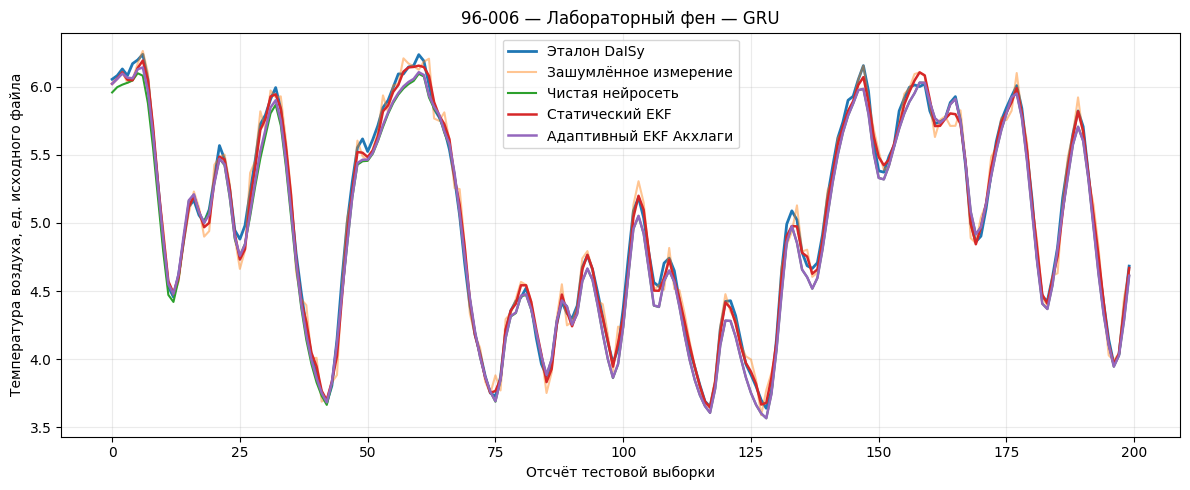

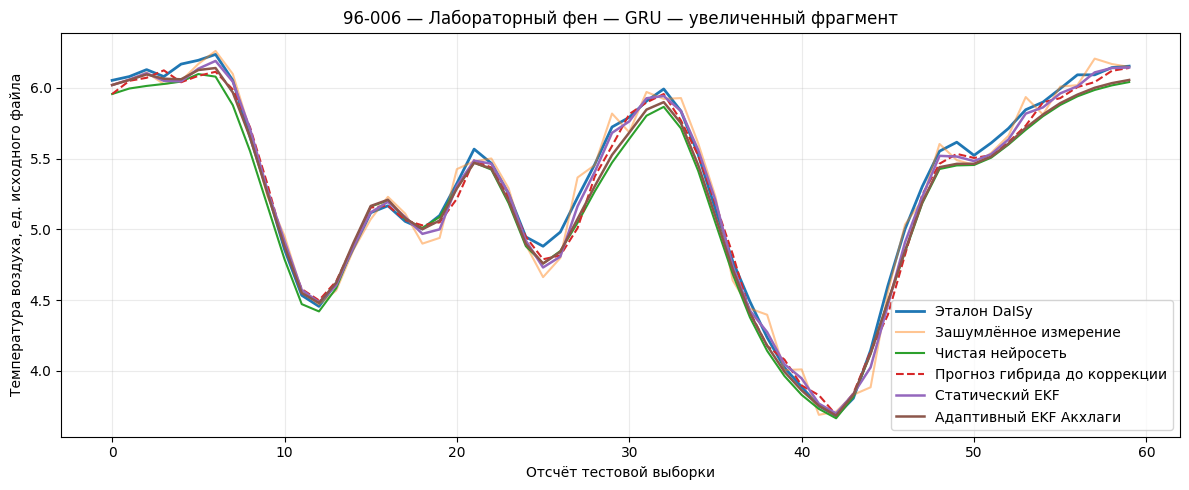

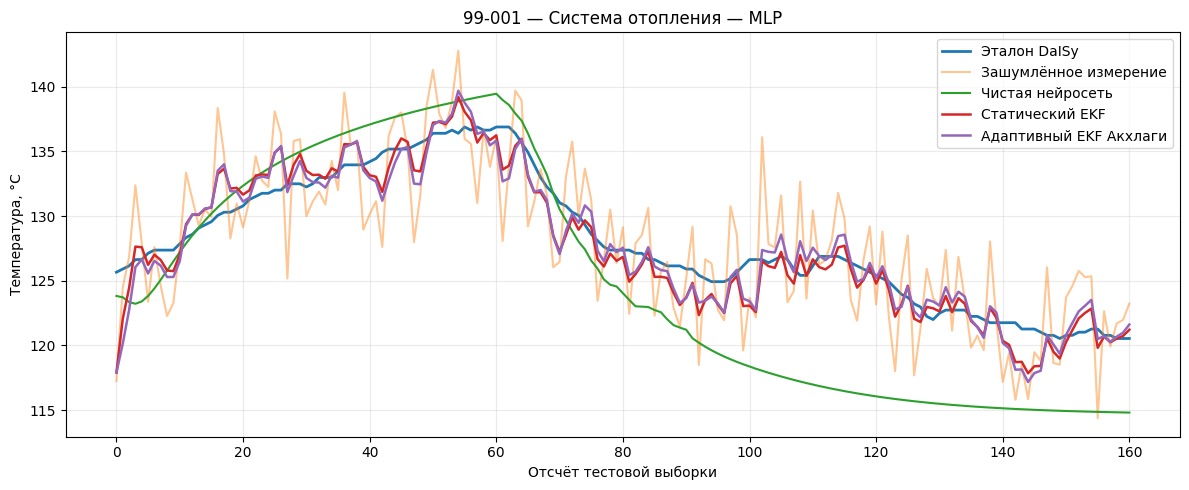

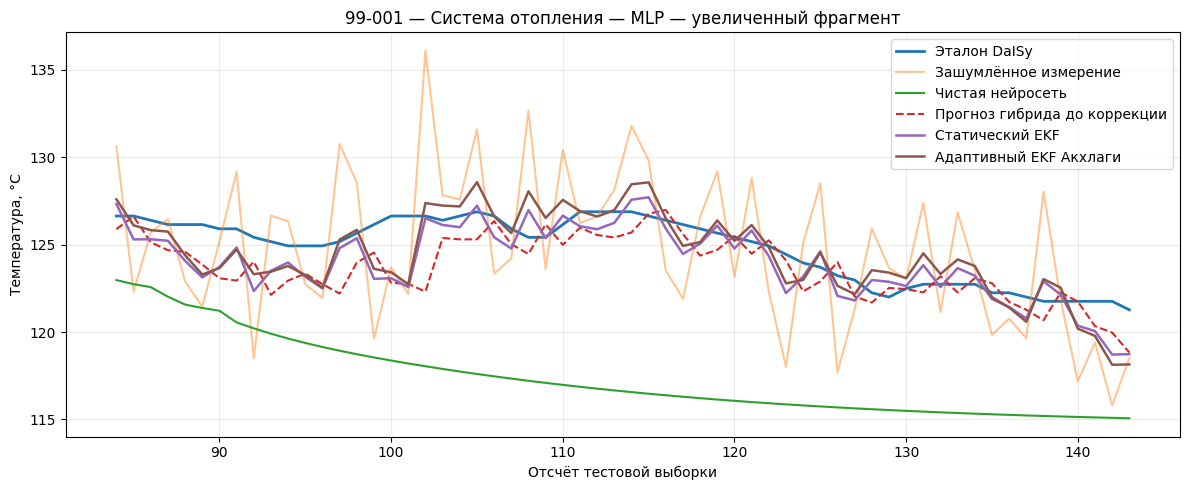

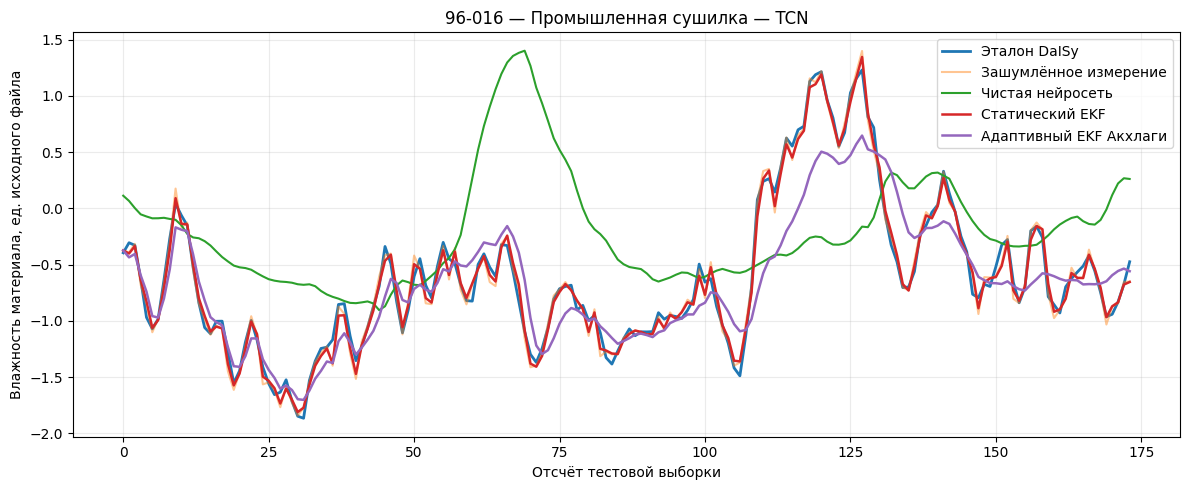

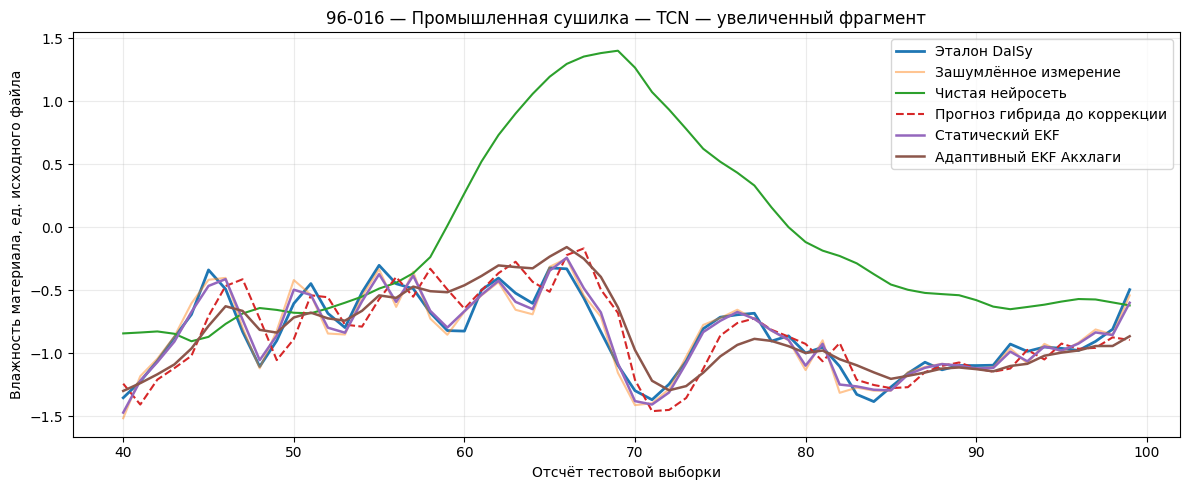

In [11]:
def zoom_bounds(reference, nn_prediction, length=60):
    error = np.abs(nn_prediction - reference)
    center = int(np.argmax(error))
    half = length // 2
    start = max(0, center - half)
    end = min(len(reference), start + length)
    start = max(0, end - length)
    return start, end


def plot_trajectory(code, data, curves, zoom=False):
    target = data['target_index']
    reference = curves['reference'][:, target]
    measurement = curves['measurement'][:, target]
    nn_prediction = curves['nn'][:, target]
    prior = curves['prior'][:, target]
    posterior = curves['posterior'][:, target]
    adaptive = curves['adaptive'][:, target]

    if zoom:
        start, end = zoom_bounds(reference, nn_prediction)
        x = np.arange(start, end)
        suffix = ' — увеличенный фрагмент'
        filename = RESULTS_DIR / f'{code}_zoom.png'
    else:
        start, end = 0, len(reference)
        x = np.arange(len(reference))
        suffix = ''
        filename = RESULTS_DIR / f'{code}_full.png'

    plt.figure(figsize=(12, 5))
    plt.plot(x, reference[start:end], linewidth=2.0, label='Эталон DaISy')
    plt.plot(x, measurement[start:end], alpha=0.45, label='Зашумлённое измерение')
    plt.plot(x, nn_prediction[start:end], label='Чистая нейросеть')
    if zoom:
        plt.plot(x, prior[start:end], linestyle='--', label='Прогноз гибрида до коррекции')
    plt.plot(x, posterior[start:end], linewidth=1.8, label='Статический EKF')
    plt.plot(x, adaptive[start:end], linewidth=1.8, label='Адаптивный EKF Акхлаги')

    plt.title(
        f'{code} — {data["name"]} — {recommended_arch[code]}{suffix}'
    )
    plt.xlabel('Отсчёт тестовой выборки')
    plt.ylabel(f"{data['output_names'][target]}, {data['output_units'][target]}")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=180)
    plt.show()


for code, data in datasets.items():
    plot_trajectory(code, data, example_curves[code], zoom=False)
    plot_trajectory(code, data, example_curves[code], zoom=True)

## 12. Итоговая таблица

Дополнительно сравниваются статический и адаптивный фильтры для одной и той же
архитектуры, выбранной на VAL. Положительный процент означает снижение RMSE
после адаптации; отрицательный — ухудшение. При нулевой исходной ошибке процент
не определён. Победитель не переопределяется по TEST.


In [12]:
final_rows = []

for code, data in datasets.items():
    arch = recommended_arch[code]
    row = comparison_tables[code].set_index('Архитектура').loc[arch]

    rmse_nn = float(row['RMSE NN'])
    rmse_measurement = float(row['RMSE измерения'])
    rmse_hybrid = float(row['RMSE NN+EKF'])
    rmse_adaptive = float(row['RMSE NN+Akhlaghi'])

    final_rows.append({
        'Датасет': code,
        'Схема': data['mode'],
        'Архитектура по VAL': arch,
        'Единицы RMSE': data['output_units'][data['target_index']],
        'Конфигурация': row['Конфигурация'],
        'Q0': row['Q0'],
        'R0': row['R0'],
        'tau': row['tau'],
        'RMSE NN': rmse_nn,
        'RMSE измерения': rmse_measurement,
        'RMSE NN+EKF': rmse_hybrid,
        'RMSE NN+Akhlaghi': rmse_adaptive,
        'Улучшение адаптивного относительно статического, %': (
            100.0 * (rmse_hybrid - rmse_adaptive) / rmse_hybrid
            if rmse_hybrid > 0 else np.nan
        ),
        'Улучшение относительно NN, %': 100.0 * (rmse_nn - rmse_hybrid) / rmse_nn,
        'Улучшение относительно измерения, %': (
            100.0 * (rmse_measurement - rmse_hybrid) / rmse_measurement
        ),
    })

final_table = pd.DataFrame(final_rows)
final_table.to_csv(RESULTS_DIR / 'final_results.csv', index=False)

display(final_table.round(5))

print('\nВсе таблицы и графики сохранены в:', RESULTS_DIR.resolve())

protocol = {
    'seed': SEED,
    'numpy_version': np.__version__,
    'torch_version': torch.__version__,
    'device': str(DEVICE),
    'epochs': EPOCHS,
    'check_every': CHECK_EVERY,
    'patience': PATIENCE,
    'min_final_epochs': MIN_FINAL_EPOCHS,
    'batch_size': BATCH_SIZE,
    'batches_per_epoch': BATCHES_PER_EPOCH,
    'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
    'normal_noise': NORMAL_NOISE,
    'noise_levels': NOISE_LEVELS,
    'q_grid': Q_GRID,
    'r_multipliers': R_MULTIPLIERS,
    'p0_alpha': P0_ALPHA,
    'mc_val': MC_VAL,
    'mc_test': MC_TEST,
    'mc_robust': MC_ROBUST,
    'candidates': CANDIDATES,
    'selected_configs': selected_configs,
    'recommended_arch': recommended_arch,
    'filter_params': filter_params,
    'adaptive_params': adaptive_params,
    'tau_grid': TAU_GRID,
    'covariance_eps': COVARIANCE_EPS,
    'architectures': ARCHITECTURES,
    'datasets': {},
}
for code, data in datasets.items():
    protocol['datasets'][code] = {
        'url': DATASET_CONFIGS[code]['url'],
        'train_end': data['train_end'],
        'val_end': data['val_end'],
        'u_mean': data['u_mean'].tolist(),
        'u_std': data['u_std'].tolist(),
        'y_mean': data['y_mean'].tolist(),
        'y_std': data['y_std'].tolist(),
    }
(RESULTS_DIR / 'protocol.json').write_text(
    json.dumps(protocol, ensure_ascii=False, indent=2), encoding='utf-8'
)


,Датасет,Схема,Архитектура по VAL,Единицы RMSE,Конфигурация,Q0,R0,tau,RMSE NN,RMSE измерения,RMSE NN+EKF,RMSE NN+Akhlaghi,"Улучшение адаптивного относительно статического, %","Улучшение относительно NN, %","Улучшение относительно измерения, %"
0,96-006,SISO,GRU,ед. исходного файла,"hidden=32, init_window=32",0.001,0.0025,0.050,0.09322,0.08525,0.05068,0.07853,-54.94666,45.63316,40.54903
1,99-001,SISO,MLP,°C,"hidden=32, control_window=32, init_window=32",0.010,0.0200,0.985,5.30115,3.82452,1.72123,1.79766,-4.44039,67.53098,54.99479
2,96-016,MIMO,TCN,ед. исходного файла,"hidden=16, control_window=16, init_window=16",0.030,0.0050,0.050,0.85571,0.09112,0.08557,0.29815,-248.43528,90.00029,6.09103



Все таблицы и графики сохранены в: /kaggle/working/daisy_hu_results


7727

Описания данных: [Hair Dryer](https://ftp.esat.kuleuven.be/pub/SISTA/data/mechanical/dryer.txt),
[Heating](https://ftp.esat.kuleuven.be/pub/SISTA/data/thermic/heating_system.txt),
[Industrial Dryer](https://ftp.esat.kuleuven.be/pub/SISTA/data/process_industry/dryer2.txt).
Также [базу DaISy](https://homes.esat.kuleuven.be/~smc/daisy/)